# MD statistics from cached data and saved reports

The first section plots fixed-reference molecular MSD and individual squared displacements from a completed MartiniFuncs cache. The next section reads LAMMPS thermo output. Both run independently of the historical report-based examples below; neither reads the large dump or runs UMA.


## Displacement from a fixed reference time: MSD₀(t)

This plot follows **time since the first selected frame**, not an average over
starting times. Whole, temporally unwrapped molecular COM coordinates come from
the analysis/cache above; no dump rereading is needed.

For molecule $m$ and the first selected time $t_0$:
$$s_m(t)=\left|\mathbf R_m(t)-\mathbf R_m(t_0)\right|^2,
\qquad \mathrm{MSD}_0(t)=\frac{1}{N}\sum_{m=1}^N s_m(t).$$

The left panel shows each species' mean. On the right, thin lines show **every
molecule** of that species and the thick black line shows their mean. All values
are in Å². Reference frame/time are printed below; `reference_molecule_ids`
maps each column in `squared_displacement_angstrom2` to persistent atom IDs.

This describes net displacement accumulated **relative to t₀**, but is not a
cumulative sum of stepwise displacements or squared steps. It can decrease when
molecules return. No drift or streaming-flow subtraction is performed. The
TOR supports any fully periodic cell (including sheared); non-periodic cells are skipped.
This plot alone does not establish diffusion or equilibration.

`REFERENCE_PLOT_POINTS=2000` limits only the plotted time samples, including both
endpoints. Calculations retain every selected frame and every molecule in
`reference_msd`. Short fluctuations can be missed by this display subsampling;
set it to `None` to draw every sample. Per-molecule results require $8TN$ bytes
for $T$ selected frames and $N$ molecules, excluding input coordinates.


Set `CACHE_DIR` below to your completed `postprocess/cache`. This section uses the entire cache, with its first frame as t₀. It requires no historical reports and no source dump. Lag-only CSVs cannot reconstruct fixed-reference displacements.


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

CACHE_DIR = None  # Set Path(r"/path/to/postprocess/cache") to enable the plots below.


In [ ]:
from MartiniFuncs.postprocessing import load_analysis_cache

result = None
if CACHE_DIR is None:
    print("Set CACHE_DIR to a completed postprocess/cache for fixed-reference MSD plots.")
else:
    result, cache_manifest = load_analysis_cache(CACHE_DIR)
    print("Loaded completed cache:", CACHE_DIR)


In [ ]:
import importlib
import MartiniFuncs.md_statistics as reference_statistics

# An open kernel may still hold the module from before this function was added.
if not hasattr(reference_statistics, "get_molecular_reference_msd"):
    reference_statistics = importlib.reload(reference_statistics)
if not hasattr(reference_statistics, "get_molecular_reference_msd"):
    raise ImportError(
        f"Update MartiniFuncs at {reference_statistics.__file__}; "
        "this installed module does not contain get_molecular_reference_msd."
    )
get_molecular_reference_msd = reference_statistics.get_molecular_reference_msd
from MartiniFuncs.trajectory_analysis import select_frame_window

REFERENCE_PLOT_POINTS = 2000  # Display only; None plots every time sample.
reference_msd, reference_molecule_ids = {}, {}
if result is None:
    print("Fixed-reference MSD skipped: CACHE_DIR is not set.")
elif result.get("com_angstrom") is None:
    print("Reference MSD unavailable: the cached unwrapping/cell convention is unsupported.")
else:
    reference_mask = select_frame_window(result)
    reference_rows = [r for r, keep in zip(result["frames"], reference_mask) if keep]
    reference_times = np.array([r["time_ps"] for r in reference_rows])
    if len(reference_times) < 2:
        print("Reference MSD needs at least two selected frames.")
    else:
        reference_species = np.asarray(result["species"])
        labels = sorted(set(reference_species))
        print(f"Reference: source frame {reference_rows[0]['frame']}, t0={reference_times[0]:g} ps")
        reference_fig, reference_axes = plt.subplots(len(labels), 2, squeeze=False,
                                                      figsize=(12, 3.5*len(labels)), layout="constrained")
        sample_count = len(reference_times) if REFERENCE_PLOT_POINTS is None else min(len(reference_times), REFERENCE_PLOT_POINTS)
        plot_indices = np.unique(np.linspace(0, len(reference_times)-1, sample_count, dtype=int))
        for row, name in enumerate(labels):
            molecule_columns = np.flatnonzero(reference_species == name)
            values = result["com_angstrom"][np.ix_(np.flatnonzero(reference_mask), molecule_columns)]
            measured = get_molecular_reference_msd(values, reference_times, unwrapped=True, selection=str(name))
            reference_msd[name] = measured
            reference_molecule_ids[name] = [result["molecule_atom_ids"][i] for i in molecule_columns]
            x = measured["elapsed_time_ps"][plot_indices]
            reference_axes[row, 0].plot(x, measured["msd_angstrom2"][plot_indices], label=f"{name}: species mean")
            reference_axes[row, 1].plot(x, measured["squared_displacement_angstrom2"][plot_indices], alpha=.3, linewidth=.7)
            reference_axes[row, 1].plot(x, measured["msd_angstrom2"][plot_indices], color="black", linewidth=2, label="Species mean")
            reference_axes[row, 0].set_title(f"{name}: MSD from t0 ({len(molecule_columns)} molecules)")
            reference_axes[row, 1].set_title(f"{name}: individual molecular squared displacements")
            for ax in reference_axes[row]:
                ax.set_xlabel("Time since reference frame (ps)")
                ax.set_ylabel("Squared COM displacement (Å²)")
                ax.grid(alpha=.25)
                ax.legend()
        plt.show()


## LAMMPS temperature and pressure from `.out` / log files

Run this section independently of the trajectory analysis below. It reads ordinary
LAMMPS `Step ...` thermo tables; it does not read atom coordinates or run UMA.
`LOAD_THERMO` enables loading. `THERMO_FILE=None` discovers a unique `.out`, `.log`
or `log*` containing a thermo table in the run directory; specify a relative or
absolute filename if multiple files match. Missing output is reported and skipped.
`THERMO_BLOCK` is a **zero-based thermo table number**, not a frame or timestep.
If several tables exist, inspect their ranges and choose one explicitly.

`thermo` retains all tables and original/custom columns; `thermo_selected` contains
the chosen table. Standard aliases include `temperature_K`, `pressure_bar`, and
energy columns when printed. The plots show raw samples, with no smoothing or
equilibrium claim. Their x-axis uses printed `Time` in ps if available, otherwise
the LAMMPS timestep. Thermo sampling need not match dump sampling.

For `metal` units, $T$ is in K and $P$ in bar
($P_{\mathrm{GPa}}=10^{-4}P_{\mathrm{bar}}$). These are **LAMMPS's printed values**;
the reader does not recompute $T=2K_{\mathrm{thermal}}/(f k_B)$ or choose its
degrees of freedom $f$. Under shear, verify which temperature compute the input
uses: parsing does not remove streaming velocity. Printed energies retain the
run's `thermo_modify norm` convention (total or per atom).

This table is kept separate from dump-derived `frames`, so it cannot silently
overwrite a differently defined temperature. For an exact-timestep join, use
`MartiniFuncs.thermo.attach_thermo` after explicitly resolving overlapping column
names. Unmatched dump samples become NaN, not interpolated values.


In [ ]:
from pathlib import Path

# This thermo section does not require the historical reports used below.
THERMO_DIRECTORY = Path(r"/path/to/simulation")
UNITS = "metal"
LOAD_THERMO = True
THERMO_FILE = None  # e.g. "simulation.out" when discovery is ambiguous
THERMO_BLOCK = None  # auto-select only if there is exactly one table


In [ ]:
from pathlib import Path
import importlib
import matplotlib.pyplot as plt
from IPython.display import display
import MartiniFuncs.thermo as thermo_io

# Refresh this stateless reader when rerunning in a previously open kernel.
thermo_io = importlib.reload(thermo_io)
thermo = thermo_selected = thermo_source = None
if LOAD_THERMO:
    thermo_source = thermo_io.discover_thermo_file(THERMO_DIRECTORY, thermo_file=THERMO_FILE)
    if thermo_source is None:
        print("No LAMMPS thermo table found; skipping thermo plots.")
    else:
        thermo = thermo_io.read_lammps_thermo(thermo_source, units=UNITS)
        print("Thermo source:", thermo_source)
        print("Available columns:", list(thermo.columns))
        blocks = thermo.groupby("thermo_block")["timestep"].agg(["min", "max", "count"])
        display(blocks.rename(columns={"min": "first_step", "max": "last_step", "count": "samples"}))
        if THERMO_BLOCK is None and len(blocks) > 1:
            print("Multiple tables: set THERMO_BLOCK to a table number above, then rerun this section.")
        else:
            selected_block = blocks.index[0] if THERMO_BLOCK is None else THERMO_BLOCK
            if selected_block not in blocks.index:
                raise ValueError(f"THERMO_BLOCK={selected_block} is absent; available: {list(blocks.index)}")
            thermo_selected = thermo.loc[thermo.thermo_block == selected_block].copy()
            display(thermo_selected.head())
else:
    print("Thermo loading disabled (LOAD_THERMO=False).")


In [ ]:
if thermo_selected is not None:
    thermo_observables = [(column, label) for column, label in
                         [("temperature_K", "LAMMPS temperature (K)"),
                          ("pressure_bar", "LAMMPS pressure (bar)")]
                         if column in thermo_selected and thermo_selected[column].notna().any()]
    if not thermo_observables:
        print("Selected table has no Temp/Press data; inspect its available columns above.")
    else:
        thermo_x = ("thermo_time_ps" if "thermo_time_ps" in thermo_selected
                    and thermo_selected["thermo_time_ps"].notna().all() else "timestep")
        thermo_fig, thermo_axes = plt.subplots(len(thermo_observables), 1, squeeze=False,
                                               figsize=(11, 3*len(thermo_observables)),
                                               sharex=True, layout="constrained")
        for ax, (column, label) in zip(thermo_axes[:, 0], thermo_observables):
            ax.plot(thermo_selected[thermo_x], thermo_selected[column], linewidth=1)
            ax.set_ylabel(label)
            ax.grid(alpha=.25)
        thermo_axes[-1, 0].set_xlabel("LAMMPS time (ps)" if thermo_x == "thermo_time_ps" else "LAMMPS timestep")
        thermo_fig.suptitle(f"{thermo_source.name} | thermo block {selected_block}")
        plt.show()


## Historical report-based examples
These remaining cells require reports generated by `python -m tests.validate_npt_statistics` and the related example scripts. They are not prerequisites for the cache-based MSD₀ or thermo plots above.


### Mathematics and report provenance
This historical notebook reads saved values; it does not rerun their estimators. The equations below describe the package calculations. Verify source report settings (especially temperature DOF, motion removal and fit windows) before interpretation. `MAX_LAG_PS` crops normalized correlation plots only. `SAVE_FIGURES` changes file output, not analysis. Dashed MSD fits use the recorded slope/intercept; dividing D by $10^{-9}$ expresses the ordinate in units of $10^{-9}$ cm²/s.


### Mathematics: pair screening, orientation and shell selection
`REACTIVE_RADIUS` $R$ (default 3.25 Å) screens the **whole CPD COM** against the mass-weighted reactive C=C center:
$$\min_{\mathbf n\in\mathbb Z^3}\|\mathbf R_{\rm CPD}+\mathbf nH-\mathbf R_{\rm CC}\|<R.$$
This is not a forming-bond distance. `MANUAL_SHIFT` / returned `shift` translates CPD by $\mathbf nH$; manual pair selection bypasses automatic screening.

Let $\mathbf a_1,\mathbf a_2$ be CPD terminal carbons and $\mathbf b_1,\mathbf b_2$ the dienophile C=C carbons in the jointly placed geometry. For the two matchings $\pi$ compute $d_i=\|\mathbf a_i-\mathbf b_{\pi(i)}\|$. Choose the smallest lexicographic tuple $(\max(d_1,d_2),d_1+d_2,\text{bond IDs})$. `forming_bonds` records those proposed atom pairs; its local variants change indices, not geometry.

Define $\mathbf u=\mathbf a_2-\mathbf a_1$, $\mathbf v=\mathbf b_2-\mathbf b_1$, $\mathbf s=(\mathbf b_1+\mathbf b_2-\mathbf a_1-\mathbf a_2)/2$. For each four-carbon reactive plane, center its coordinates into $X$ and take the last right singular vector of $X=U\Sigma V^T$ as its unit normal $\mathbf n$. Then
$$A(\mathbf p,\mathbf q)=\frac{180}{\pi}\arccos\!\left(\frac{|\mathbf p\cdot\mathbf q|}{\|\mathbf p\|\|\mathbf q\|}\right),$$
$$\theta_{\rm axis}=A(\mathbf u,\mathbf v),\quad\theta_{\rm plane}=A(\mathbf n_{\rm CPD},\mathbf n_{\rm MAL}),\quad\theta_{\rm approach}=A(\mathbf n_{\rm CPD},\mathbf s).$$
The implementation clips the cosine to [0,1]; these unoriented angles lie in [0°,90°]. Degenerate geometry is rejected. `CRITERIA` / `PAIR_CRITERIA` compare $\max d_i$, $|d_1-d_2|$, and each angle with their corresponding `max_*` fields (Å or degrees). Equality passes; `None` disables that numerical test. They do not establish a transition state or stereochemistry.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "reports/npt_statistics").is_dir():
    ROOT = ROOT.parent
REPORT_DIR = ROOT / "reports/npt_statistics"
OUTPUT_DIR = REPORT_DIR / "plots"
SAVE_FIGURES = False  # Set True to export PNG and PDF.
MAX_LAG_PS = 10.0    # Correlation display range; does not recompute correlations.

required = [REPORT_DIR / name for name in ("summary.json", "frames.csv", "pair_lifetimes.json")]
if not all(path.is_file() for path in required):
    raise FileNotFoundError("Generate reports first with python -m tests.validate_npt_statistics")
summary = json.loads(required[0].read_text())
frames = pd.read_csv(required[1])
episodes = pd.DataFrame(json.loads(required[2].read_text()))
if len(frames) != summary["frames"] or len(episodes) != summary["pair_episode_count"]:
    raise ValueError("Report lengths disagree; regenerate the reports together")
if not np.all(np.diff(frames["time_ps"]) > 0):
    raise ValueError("Frame timestamps must increase")
print(f"{len(frames):,} frames; {summary['atoms']:,} atoms; "
      f"{frames.time_ps.iloc[0]:g}–{frames.time_ps.iloc[-1]:g} ps")
print("Source:", summary["dump"])
print("Pair-detection failures:", len(summary["pair_detection_failures"]))

plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
COLORS = {"CPD": "#177E89", "dienophile": "#C65B28"}

def finish(fig, name):
    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
        fig.savefig(OUTPUT_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()


2,001 frames; 1,360 atoms; 0–1000 ps
Source: C:\Users\nicho\Documents\Martini collab\MartiniFuncs\tests\lammpsio_tests\equilibrate_2p5.lammpstrj
Pair-detection failures: 0


## Whole-frame histories
Raw samples are shown without smoothing or removal of equilibration frames. The dashed lines show whole-run means, not fitted equilibrium values. Temperature uses the report's explicit 3N−3 degrees of freedom. Missing pair counts remain gaps.

### Mathematics: whole-frame density and kinetic temperature
For $N$ atoms, cell matrix $H$ (Å), masses $m_i$ (amu) and velocities $\mathbf v_i$:
$$V=|\det H|,\qquad \rho=1.66053906660\,\frac{\sum_i m_i}{V}\quad[\mathrm{g/cm^3}],$$
$$K=\tfrac12\sum_i m_i|\mathbf v_i|^2,\qquad T=\frac{2K}{f_{\rm DOF}k_B}.$$
Kinetic energy is evaluated in ASE's internal mass/velocity units, giving eV; $k_B$ is in eV/K. `TEMPERATURE_DOF` supplies $f_{\rm DOF}$; `"3N-3"` sets $f_{\rm DOF}=3N-3$ and `None` omits temperature. **Current notebook calls do not subtract COM velocity.** Choosing $3N-3$ changes only the denominator; it does not remove drift. A drift-corrected calculation instead uses $\mathbf v_i-\mathbf V$, where $\mathbf V=\sum_i m_i\mathbf v_i/\sum_i m_i$, and requires `remove_com=True`. Constraints require their own DOF accounting. Notebook 08 omits this derived temperature and can accept a documented thermo temperature instead.

A displayed whole-run mean is $\bar x=\sum_{j=0}^{T-1}x_j/T$; it averages saved frames, not independent samples.


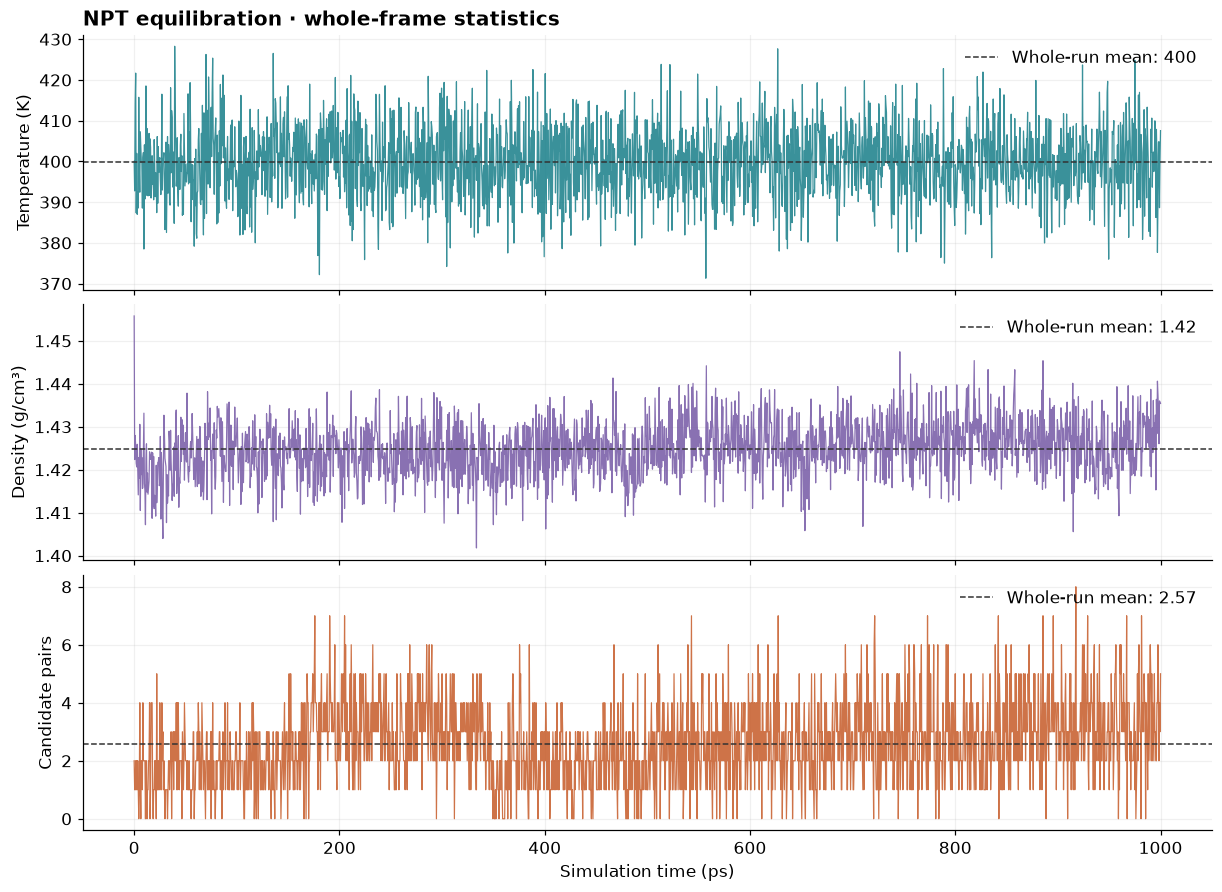

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, layout="constrained")
for ax, column, label, color in zip(
        axes, ["temperature_K", "density_g_cm3", "candidate_pairs"],
        ["Temperature (K)", "Density (g/cm³)", "Candidate pairs"],
        ["#177E89", "#7558A5", "#C65B28"]):
    ax.plot(frames.time_ps, frames[column], color=color, lw=0.8, alpha=0.85)
    mean = frames[column].mean()
    ax.axhline(mean, color="#333333", linestyle="--", linewidth=1,
               label=f"Whole-run mean: {mean:.3g}")
    ax.set_ylabel(label)
    ax.grid(alpha=0.18)
    ax.legend(loc="upper right", frameon=False)
axes[-1].set_xlabel("Simulation time (ps)")
axes[0].set_title("NPT equilibration · whole-frame statistics", loc="left", weight="bold")
finish(fig, "frame_histories")


## Observed encounter durations
Each episode is one continuous run of detections of the same two molecules. An episode seen once has a **zero observed span**, meaning its duration is unresolved—not that the physical encounter was instantaneous. Boundary-censored episodes are separated from completed episodes. These are sampled duration distributions, not survival estimates or unbiased physical lifetimes.

### Mathematics: pair counts and observed lifetimes
A pair identity consists of two molecular atom-ID sets. The count at sample $j$ is $n_j=|P_j|$, where $P_j$ is that frame's accepted pair set. `COMPUTE_PAIRS` controls whether these sets are calculated; `PAIR_BACKEND` changes topology reuse, while `PAIR_WORKERS` and `PAIR_BATCH_SIZE` change task scheduling, not the equations (at most $2\times$ workers batches outstanding).

Consecutive detections of one identity define an encounter. These notebooks use the default zero allowed gap. Its observed span is
$$t_{\rm last\ detected}-t_{\rm first\ detected}.$$
A single-frame span is zero and its true duration is unresolved. Left/right censoring means the encounter touches the selected window boundary; completed-only histograms exclude these records. Histogram bin counts sum indicator functions for the displayed span intervals; a log y-axis changes display only. Histograms are not censoring-corrected lifetime estimates. Fixed-topology pair screening does not establish that no reaction occurred; notebook 08 has a separate size screen.


2,280/3,220 episodes have unresolved single-frame durations.


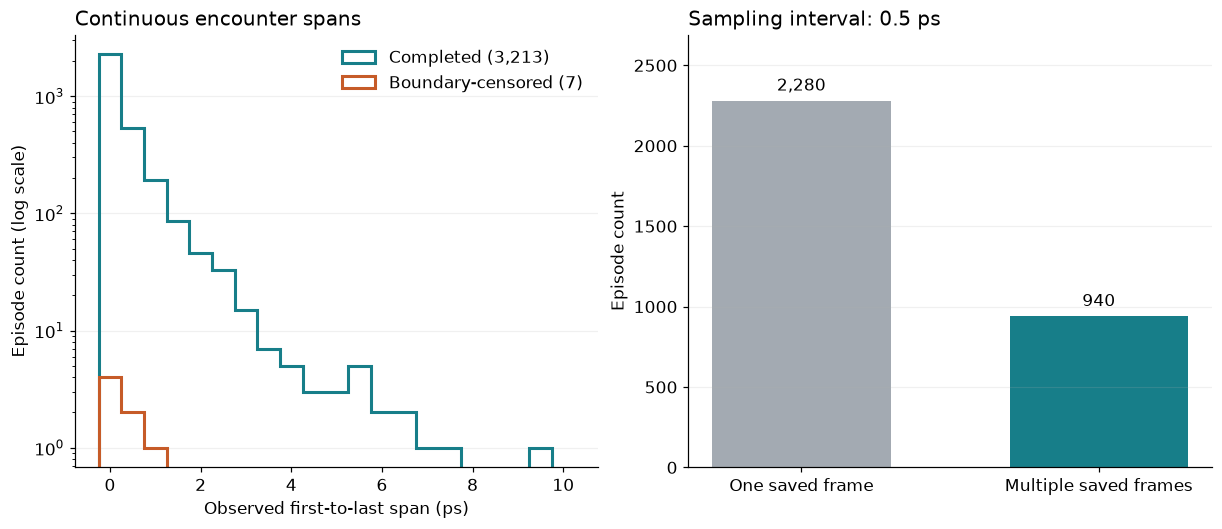

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.7), layout="constrained")
if episodes.empty:
    for ax in axes:
        ax.text(.5, .5, "No pair episodes", transform=ax.transAxes, ha="center")
else:
    censored = episodes.left_censored | episodes.right_censored
    spacing = float(summary["sample_interval_ps"])
    maximum = float(episodes.observed_span_ps.max())
    bins = np.arange(-spacing/2, maximum + 1.51*spacing, spacing)
    for mask, label, color in [(~censored, "Completed", "#177E89"),
                                (censored, "Boundary-censored", "#C65B28")]:
        axes[0].hist(episodes.loc[mask, "observed_span_ps"], bins=bins,
                     histtype="step", linewidth=2, color=color, label=f"{label} ({mask.sum():,})")
    axes[0].set_yscale("log")
    axes[0].set_ylabel("Episode count (log scale)")
    axes[0].set_xlabel("Observed first-to-last span (ps)")
    axes[0].legend(frameon=False)
    axes[0].set_title("Continuous encounter spans", loc="left")
    counts = [(episodes.detected_frames == 1).sum(), (episodes.detected_frames > 1).sum()]
    bars = axes[1].bar(["One saved frame", "Multiple saved frames"], counts,
                       color=["#A3AAB2", "#177E89"], width=.6)
    axes[1].bar_label(bars, labels=[f"{n:,}" for n in counts], padding=4)
    axes[1].set_ylim(0, max(counts) * 1.18)
    axes[1].set_ylabel("Episode count")
    axes[1].set_title(f"Sampling interval: {spacing:g} ps", loc="left")
    print(f"{counts[0]:,}/{len(episodes):,} episodes have unresolved single-frame durations.")
for ax in axes:
    ax.grid(axis="y", alpha=.18)
finish(fig, "pair_durations")


## Molecular velocity and resultant-force correlations
Each curve uses the report's full-trajectory time-origin average and is normalized by its own zero-lag value, C(t)/C(0). This emphasizes decay rather than magnitude; the zero-lag values are printed with physical units. The saved calculations do not subtract temporal means. With 0.5 ps sampling, faster dynamics are unresolved. Changing `MAX_LAG_PS` only changes the displayed range.

### Mathematics: molecular motion, MSD and correlations
For molecule $m$ of mass $M_m=\sum_{i\in m}m_i$, first reconstruct whole coordinates across periodic bonds:
$$\mathbf R_m=\frac{\sum_{i\in m}m_i\mathbf r_i}{M_m},\quad
\mathbf V_m=\frac{\sum_{i\in m}m_i\mathbf v_i}{M_m},\quad
\mathbf F_m=\sum_{i\in m}\mathbf F_i.$$
$\mathbf R_m$ is in Å, $\mathbf V_m$ in Å/ps, $\mathbf F_m$ in eV/Å. Whole-molecule COMs are temporally unwrapped by TOR, componentwise:
$$\mathbf d_j=\mathbf w_j-\mathbf w_{j-1},\quad
\Delta\mathbf r_j=\mathbf d_j-\mathbf L_j\left\lfloor\mathbf d_j/\mathbf L_j+\tfrac12\right\rfloor,\quad
\mathbf u_j=\mathbf u_{j-1}+\Delta\mathbf r_j.$$
$\mathbf w_j$ is the centered wrapped COM, $\mathbf L_j$ the destination box lengths, $\mathbf u_0=\mathbf w_0$. `analyze_run` updates this on every source frame before striding. This requires fixed-center orthorhombic periodic cells and sufficiently frequent source frames; no drift subtraction or finite-size correction is applied.

With $T$ selected samples and $M$ molecules of one species, lag $\tau_k=k\Delta t$:
$$\mathrm{MSD}(\tau_k)=\frac{\sum_{j=0}^{T-k-1}\sum_{m=1}^M|\mathbf u_{j+k,m}-\mathbf u_{j,m}|^2}{M(T-k)},\qquad N_{\rm origins}=T-k,$$
$$C_X(\tau_k)=\frac{\sum_{j=0}^{T-k-1}\sum_m\mathbf X_{j,m}\cdot\mathbf X_{j+k,m}}{M(T-k)}.$$
$X=V$ gives VACF in (Å/ps)²; $X=F$ gives force correlation in (eV/Å)². No temporal mean is subtracted. Plots use $C_X(\tau)/C_X(0)$ when $C_X(0)>0$. Overlapping origins are correlated. `MAX_LAG_PS` $\tau_{\max}$ retains $k\le\min(T-1,\lfloor\tau_{\max}/\Delta t\rfloor)$ in the directory workflows; in the historical report viewer it only crops the display.

If `DIFFUSION_FIT_PS=(a,b)` is supplied, an unweighted free-intercept fit minimizes
$$\sum_{a\le\tau_k\le b}[\mathrm{MSD}(\tau_k)-c-s\tau_k]^2,\qquad D=s/6.$$
$D$ in Å²/ps is multiplied by $10^{-4}$ for cm²/s or $10^{-8}$ for m²/s. Fit residual RMS is $\sqrt{\mathrm{mean}[(\mathrm{MSD}-c-s\tau)^2]}$ (Å²); it is **not** uncertainty in $D$. Notebook 08 adds the block checks below.


CPD velocity C(0) = 15.0348 (Å/ps)²
dienophile velocity C(0) = 5.25909 (Å/ps)²
CPD net_force C(0) = 0.389105 (eV/Å)²
dienophile net_force C(0) = 0.783052 (eV/Å)²


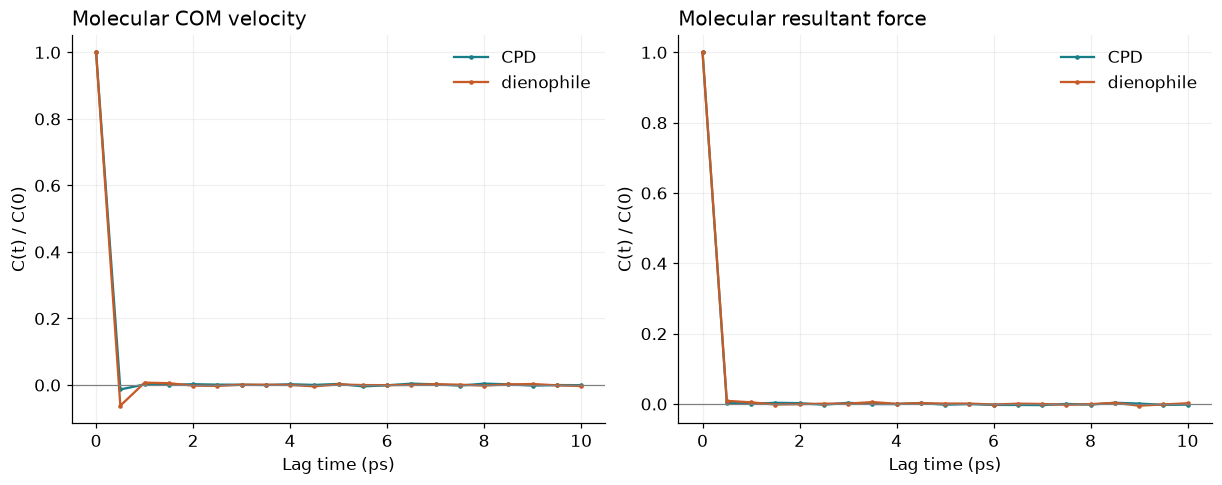

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), layout="constrained")
for ax, quantity, title, units in zip(axes, ["velocity", "net_force"],
        ["Molecular COM velocity", "Molecular resultant force"], ["(Å/ps)²", "(eV/Å)²"]):
    for species, data in summary["correlations"].items():
        lag = np.asarray(data[quantity]["lag_ps"])
        values = np.asarray(data[quantity]["correlation"])
        if values[0] <= 0:
            raise ValueError(f"Cannot normalize {species} {quantity}: C(0) <= 0")
        mask = lag <= MAX_LAG_PS
        ax.plot(lag[mask], values[mask]/values[0], ".-", color=COLORS.get(species),
                label=species, markersize=4)
        print(f"{species} {quantity} C(0) = {values[0]:.6g} {units}")
    ax.axhline(0, color="gray", lw=.8)
    ax.set_xlabel(r"Lag $\tau$ (ps)")
    ax.set_ylabel("C(t) / C(0)")
    ax.set_title(title, loc="left")
    ax.legend(frameon=False)
    ax.grid(alpha=.18)
finish(fig, "molecular_correlations")


## Molecular diffusion in the last half and last quarter

Compare trajectory times **500-1000 ps** and **750-1000 ps**, excluding the initial equilibration period. Each species contains 40 molecules. Molecules are made whole before TOR COM unwrapping for the orthorhombic NPT cell ([method reference](https://doi.org/10.1021/acs.jctc.3c00308)). No drift subtraction or finite-size correction is applied.

Trajectory windows select frames; lag intervals select displacement times within those frames. We fit MSD = intercept + 6 D lag over identical 10-50, 25-75, and 50-100 ps lag intervals in both trajectory windows. The overlapping windows are not independent replicates, and fit-window spread is not a confidence interval.

Run `python -m examples.analyze_npt_diffusion` to create the COM cache, then `python -m examples.check_diffusion_windows` to analyze these late windows without rereading the dump.


In [6]:
diffusion_path = REPORT_DIR / "diffusion/late_windows.json"
if not diffusion_path.exists():
    raise FileNotFoundError("Run python -m examples.check_diffusion_windows first")
diffusion = json.loads(diffusion_path.read_text())
fit_rows = []
for species, windows in diffusion["species"].items():
    for data in windows:
        start, end = data["trajectory_window_ps"]
        for fit in data["fits"]:
            lo, hi = fit["fit_interval_ps"]
            fit_rows.append({"species": species, "trajectory (ps)": f"{start}-{end}",
                             "lag fit (ps)": f"{lo:g}-{hi:g}",
                             "D (cm^2/s)": fit["diffusion_cm2_per_s"]})
print(pd.DataFrame(fit_rows).to_string(index=False, float_format=lambda x: f"{x:.3e}"))


   species trajectory (ps) lag fit (ps)  D (cm^2/s)
       CPD        500-1000        10-50   7.683e-09
       CPD        500-1000        25-75   5.745e-09
       CPD        500-1000       50-100   5.841e-09
       CPD        750-1000        10-50   4.065e-09
       CPD        750-1000        25-75   2.962e-09
       CPD        750-1000       50-100   2.701e-09
dienophile        500-1000        10-50   4.138e-09
dienophile        500-1000        25-75   2.447e-09
dienophile        500-1000       50-100   1.809e-09
dienophile        750-1000        10-50   3.199e-09
dienophile        750-1000        25-75   2.155e-09
dienophile        750-1000       50-100   1.647e-09


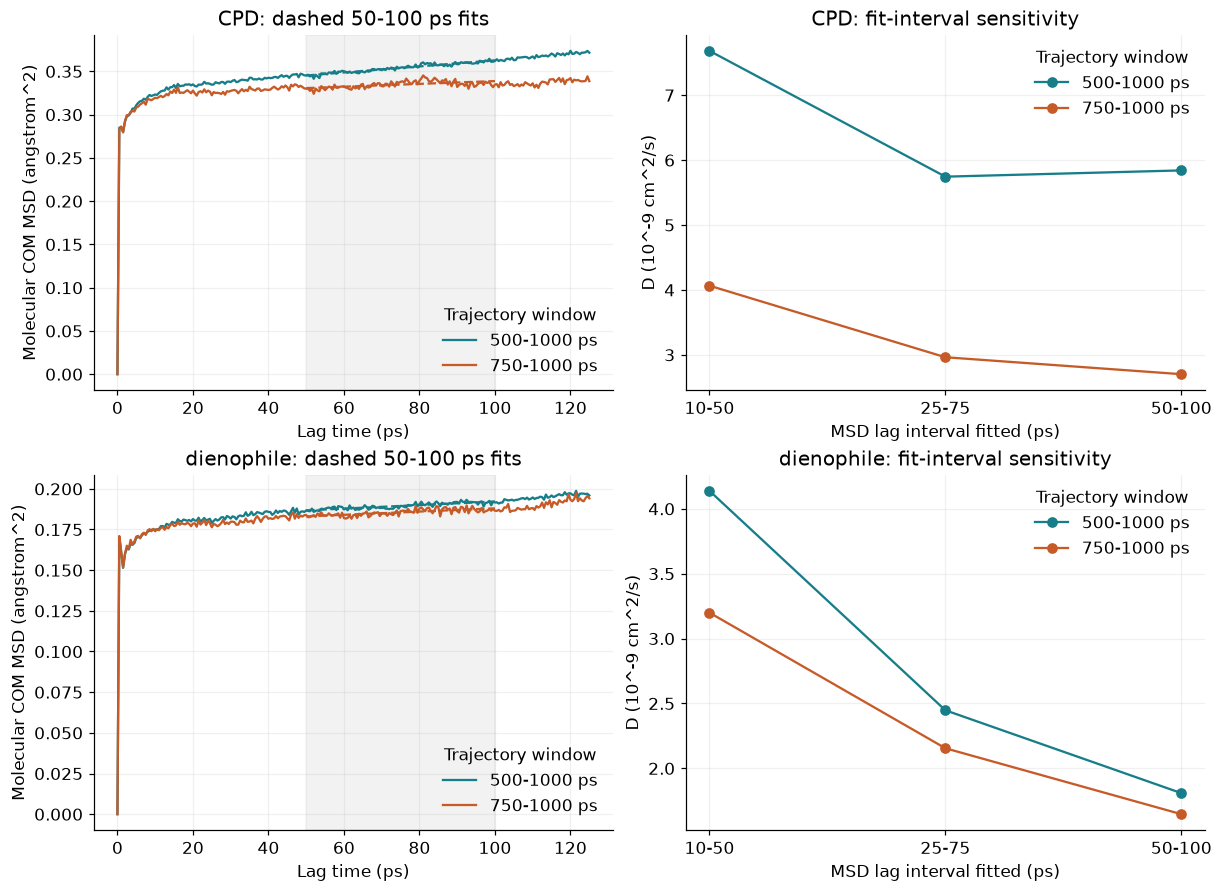

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
for row, (species, windows) in enumerate(diffusion["species"].items()):
    for data, color in zip(windows, ["#177E89", "#C65B28"]):
        start, end = data["trajectory_window_ps"]
        label = f"{start}-{end} ps"
        lag = np.asarray(data["lag_ps"])
        msd = np.asarray(data["msd_angstrom2"])
        view = lag <= 125
        axes[row, 0].plot(lag[view], msd[view], color=color, label=label)
        primary = data["fits"][-1]
        fitted_lag = np.asarray(primary["fit_interval_ps"])
        axes[row, 0].plot(fitted_lag, primary["intercept_angstrom2"] +
                          primary["slope_angstrom2_per_ps"] * fitted_lag,
                          color=color, ls="--", lw=1.5)
        labels = [f"{f['fit_interval_ps'][0]:g}-{f['fit_interval_ps'][1]:g}"
                  for f in data["fits"]]
        axes[row, 1].plot(labels, [f["diffusion_cm2_per_s"] / 1e-9 for f in data["fits"]],
                          "o-", color=color, label=label)
    axes[row, 0].axvspan(50, 100, color="gray", alpha=.10)
    axes[row, 0].set(xlabel=r"Lag $\tau$ (ps)", ylabel=r"Molecular COM MSD($\tau$) ($\mathrm{\AA}^2$)",
                     title=f"{species}: dashed 50-100 ps fits")
    axes[row, 1].set(xlabel="MSD lag interval fitted (ps)", ylabel="D (10^-9 cm^2/s)",
                     title=f"{species}: fit-interval sensitivity")
for ax in axes.flat:
    ax.legend(frameon=False, title="Trajectory window")
    ax.grid(alpha=.18)
finish(fig, "molecular_diffusion")


With 50-100 ps lag fits, CPD gives 5.84e-9 cm^2/s in the last half and 2.70e-9 in the last quarter; the dienophile gives 1.81e-9 and 1.65e-9 cm^2/s, respectively. The dienophile agrees more closely across trajectory windows at this lag interval, while CPD remains sensitive to the selected trajectory window. Shorter lag fits yield larger coefficients, especially for the dienophile.

These are finite-window estimates. Early equilibration data are excluded; their disagreement with late data is not evidence against late-time equilibration. The remaining late-window and lag-interval sensitivity should be assessed before choosing a single equilibrium diffusion coefficient.


## Late-time stability diagnostics

Four disjoint blocks cover 500 <= time < 1000 ps. Each has 250 frames; the final endpoint is excluded to keep equal sample counts. Run `python -m examples.analyze_npt_stability` after refreshing the COM cache with `python -m examples.analyze_npt_diffusion`.

Temperature and density distributions broadly overlap. COM RDFs and nearest-neighbor distributions also change little across blocks. Candidate-count means, however, increase from 2.528 to 3.224 (27.5%), and their batch-mean error estimate continues to increase with batch duration. Thus the bulk diagnostics look comparatively steady, while stability of the reaction-relevant population remains unresolved. A slowly changing population and limited sampling are both possible explanations.

The plotted errors assume independent batches; the four longest batches provide a noisy estimate. No equilibrium verdict or confidence interval is claimed. Potential energy, pressure, reactive orientations, and independent replicas are not assessed. The report uses actual wrapped COM coordinates in each NPT box, not temporally unwrapped diffusion coordinates.


### Mathematics: scalar summaries and batch uncertainty
For $T$ samples $x_j$, compute $\bar x=T^{-1}\sum_jx_j$ and sample standard deviation $s_x=\sqrt{\sum_j(x_j-\bar x)^2/(T-1)}$. `N_BLOCKS` divides the selected samples into that many consecutive near-equal sections (earlier sections receive remainders). These section summaries differ from the smaller **batches** used to estimate errors.

`BATCH_DURATIONS_PS` $d$ is converted to $b=\max(2,\mathrm{round}(d/\Delta t))$ samples (NumPy/Python nearest-even rounding); only $B=\lfloor T/b\rfloor$ complete batches enter
$$\bar x_q=\frac1b\sum_{j=qb}^{(q+1)b-1}x_j,\qquad\mathrm{SE}(\bar x)=\frac{s_{\bar x_q}}{\sqrt B}.$$
The discarded tail is $T-Bb$ samples. The plotted batch duration is $b\Delta t$; the first-to-last sample span is $(b-1)\Delta t$. SE assumes batches are sufficiently independent. Check whether it stabilizes as batch size increases; a small SE alone is not proof of equilibrium.

`get_series_statistics` also uses a free-intercept least-squares scalar drift slope and empirical 5/50/95 percentiles. Its normalized ACF is
$$\rho_k=\frac{\sum_{j=0}^{T-k-1}(x_j-\bar x)(x_{j+k}-\bar x)}{(T-k)\,T^{-1}\sum_j(x_j-\bar x)^2},\quad
g=1+2\sum_{k=1}^{K-1}\rho_k,\quad N_{\rm eff}=T/g,\quad\tau_c=\Delta t\,g/2.$$
$K$ is the first nonpositive ACF lag (or the available end). These correlation estimates are heuristics, not equilibrium tests.


### Mathematics: molecular RDF and nearest neighbors
Use instantaneous whole-molecule **wrapped** COMs, not accumulated TOR positions. For orthorhombic box lengths $\mathbf L_t$:
$$\mathbf d_{ij}=\mathbf R_j-\mathbf R_i-\mathbf L_t\left\lfloor(\mathbf R_j-\mathbf R_i)/\mathbf L_t+\tfrac12\right\rfloor.$$
For radial bin $[r_l,r_{l+1})$, let $n_{tl}$ count pair distances in that bin and $V_l=4\pi(r_{l+1}^3-r_l^3)/3$. Then
$$g_l=\frac1{T_s}\sum_{t\in\mathrm{sampled}}\frac{n_{tl}\prod_\alpha L_{t\alpha}}{P V_l},\quad
P=\begin{cases}M_A M_B&A\ne B,\\M_A(M_A-1)/2&A=B.\end{cases}$$
Like-species pairs are counted once, self-pairs excluded. Bin centers are $(r_l+r_{l+1})/2$. `RDF_BINS` sets the number of equal-width bins where configurable; notebook 05 fixes 64 bins and ends at $0.999\min_{t,\alpha}L_{t\alpha}/2$. Notebook 08 ends at half the shortest selected box edge, divides the window into four chronological sections, and samples every `STRUCTURE_STRIDE`-th retained frame **within each section**. These are descriptive curves without uncertainty bands.

Nearest-neighbor distances are $d_{ti}^{\rm nearest}=\min_j\|\mathbf d_{ij}\|$ (exclude self); the reported mean averages over central molecules and frames. Nearest distances are not limited by the RDF bin range.


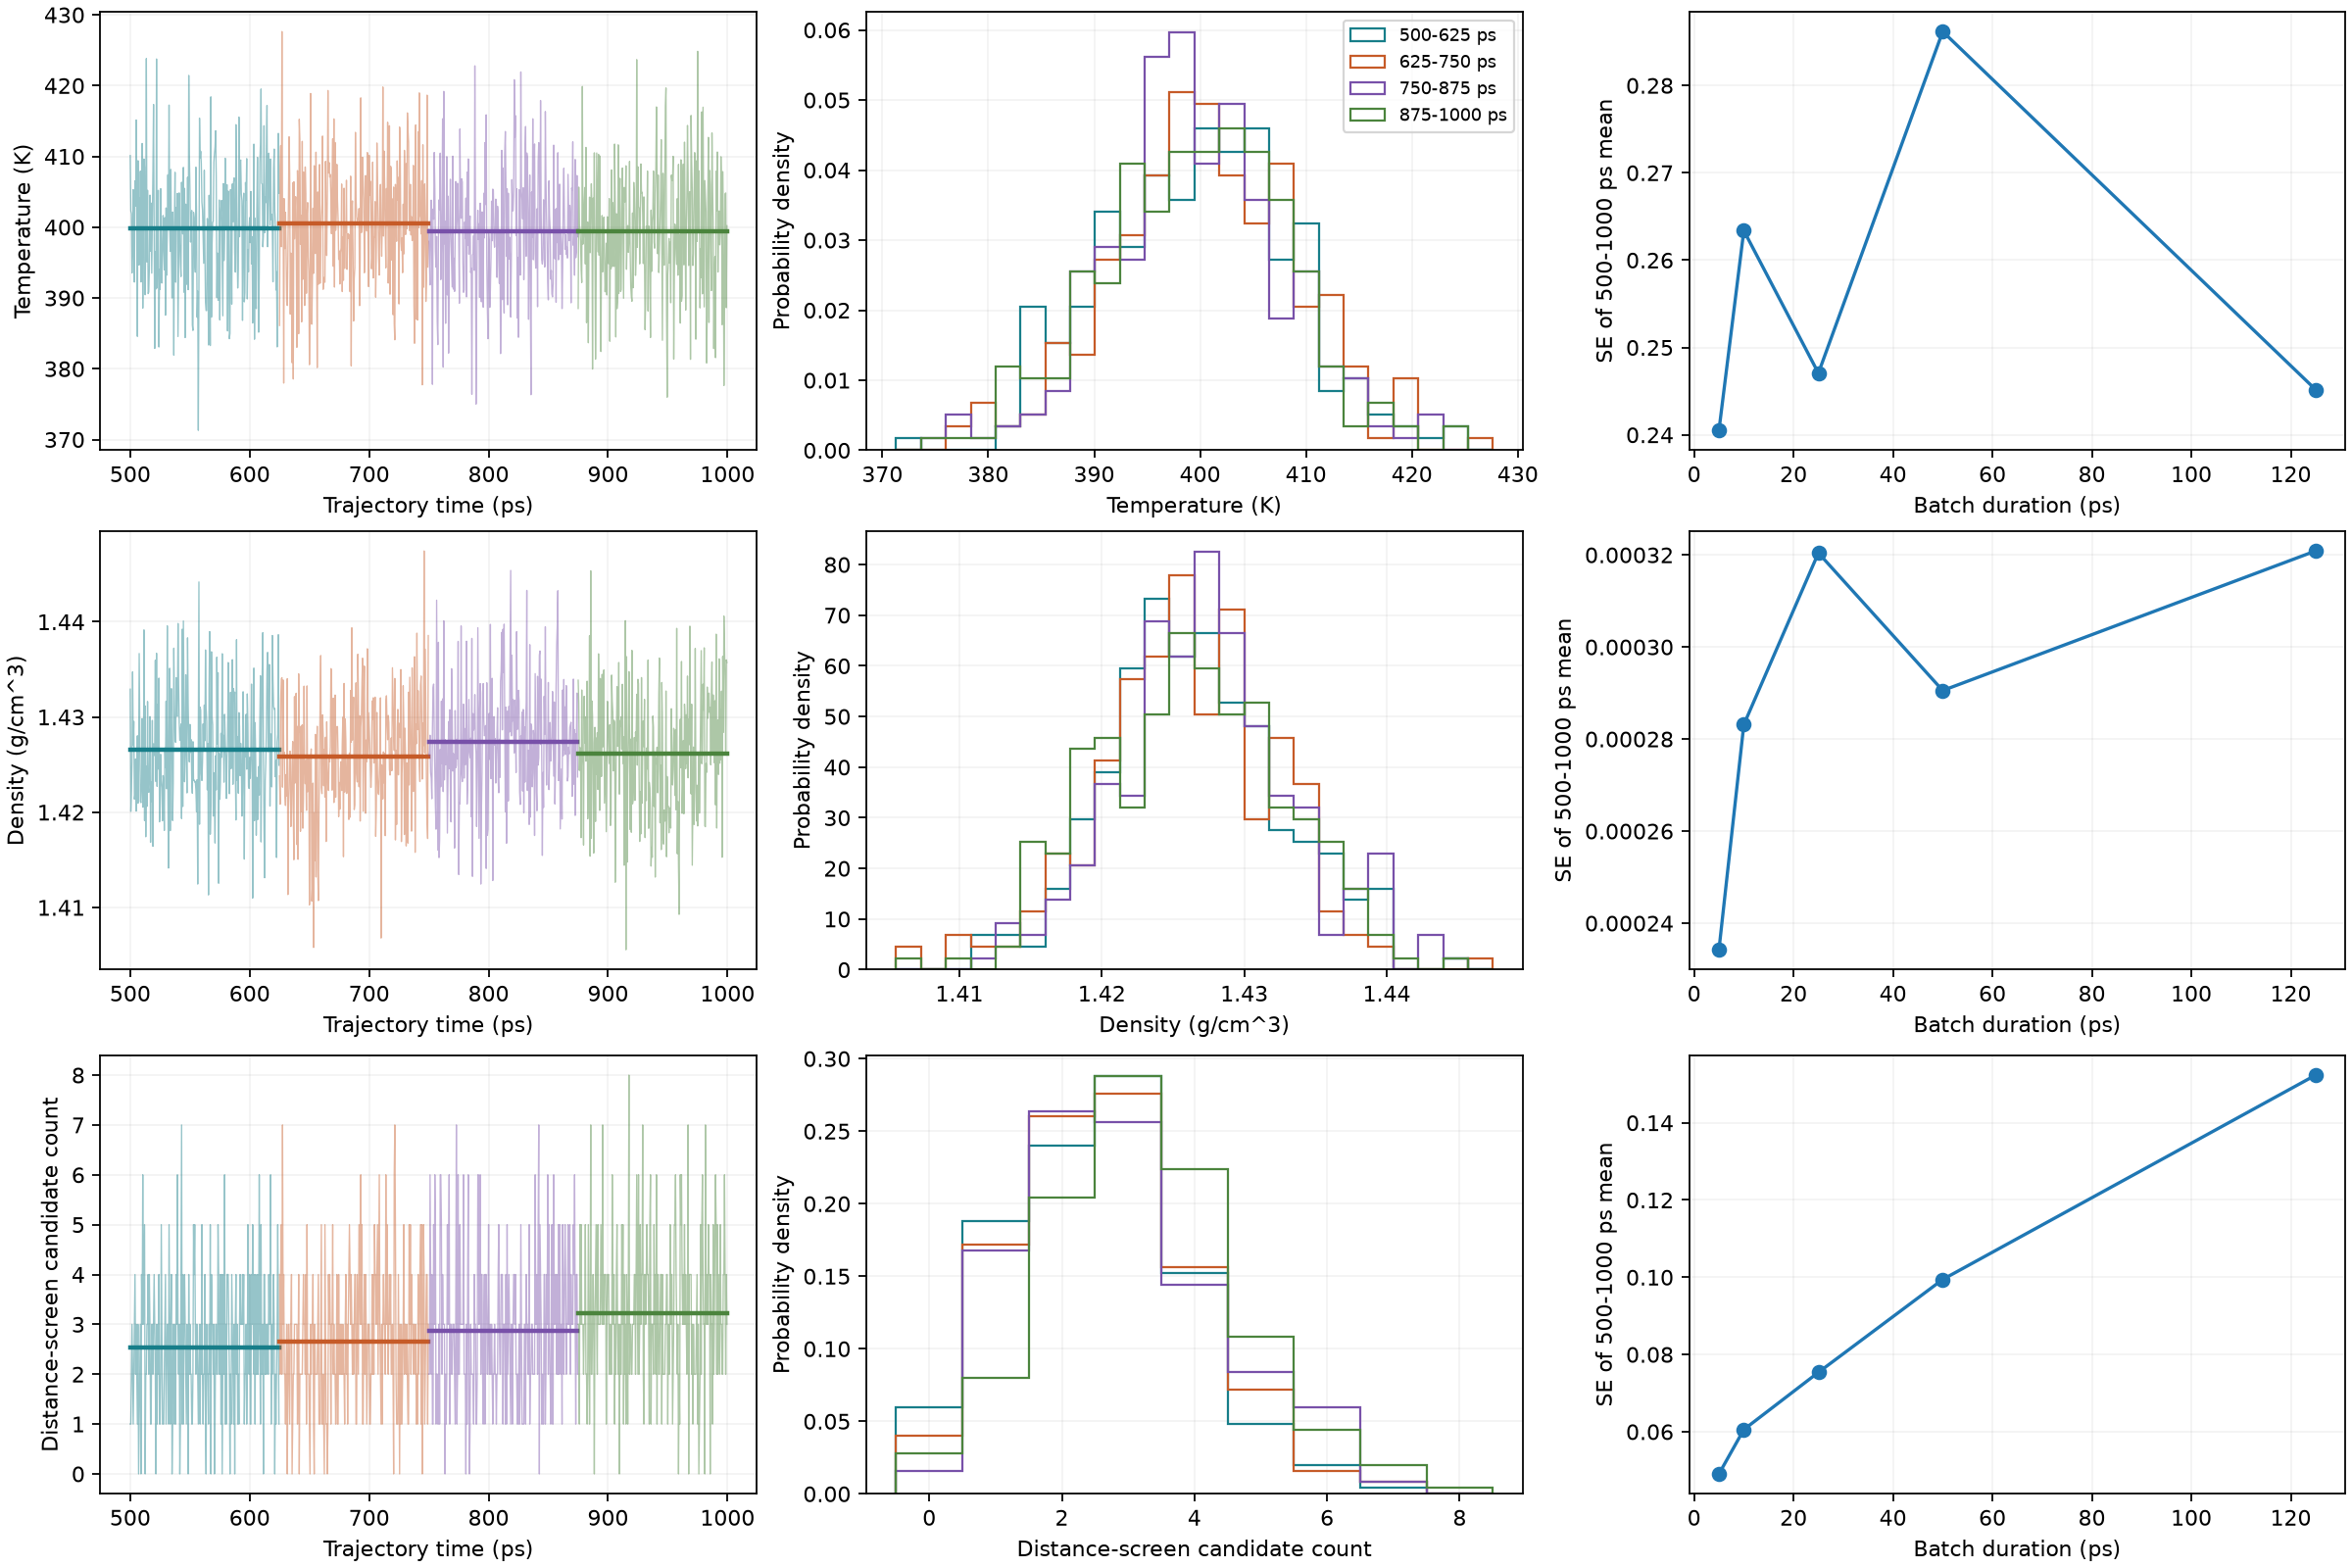

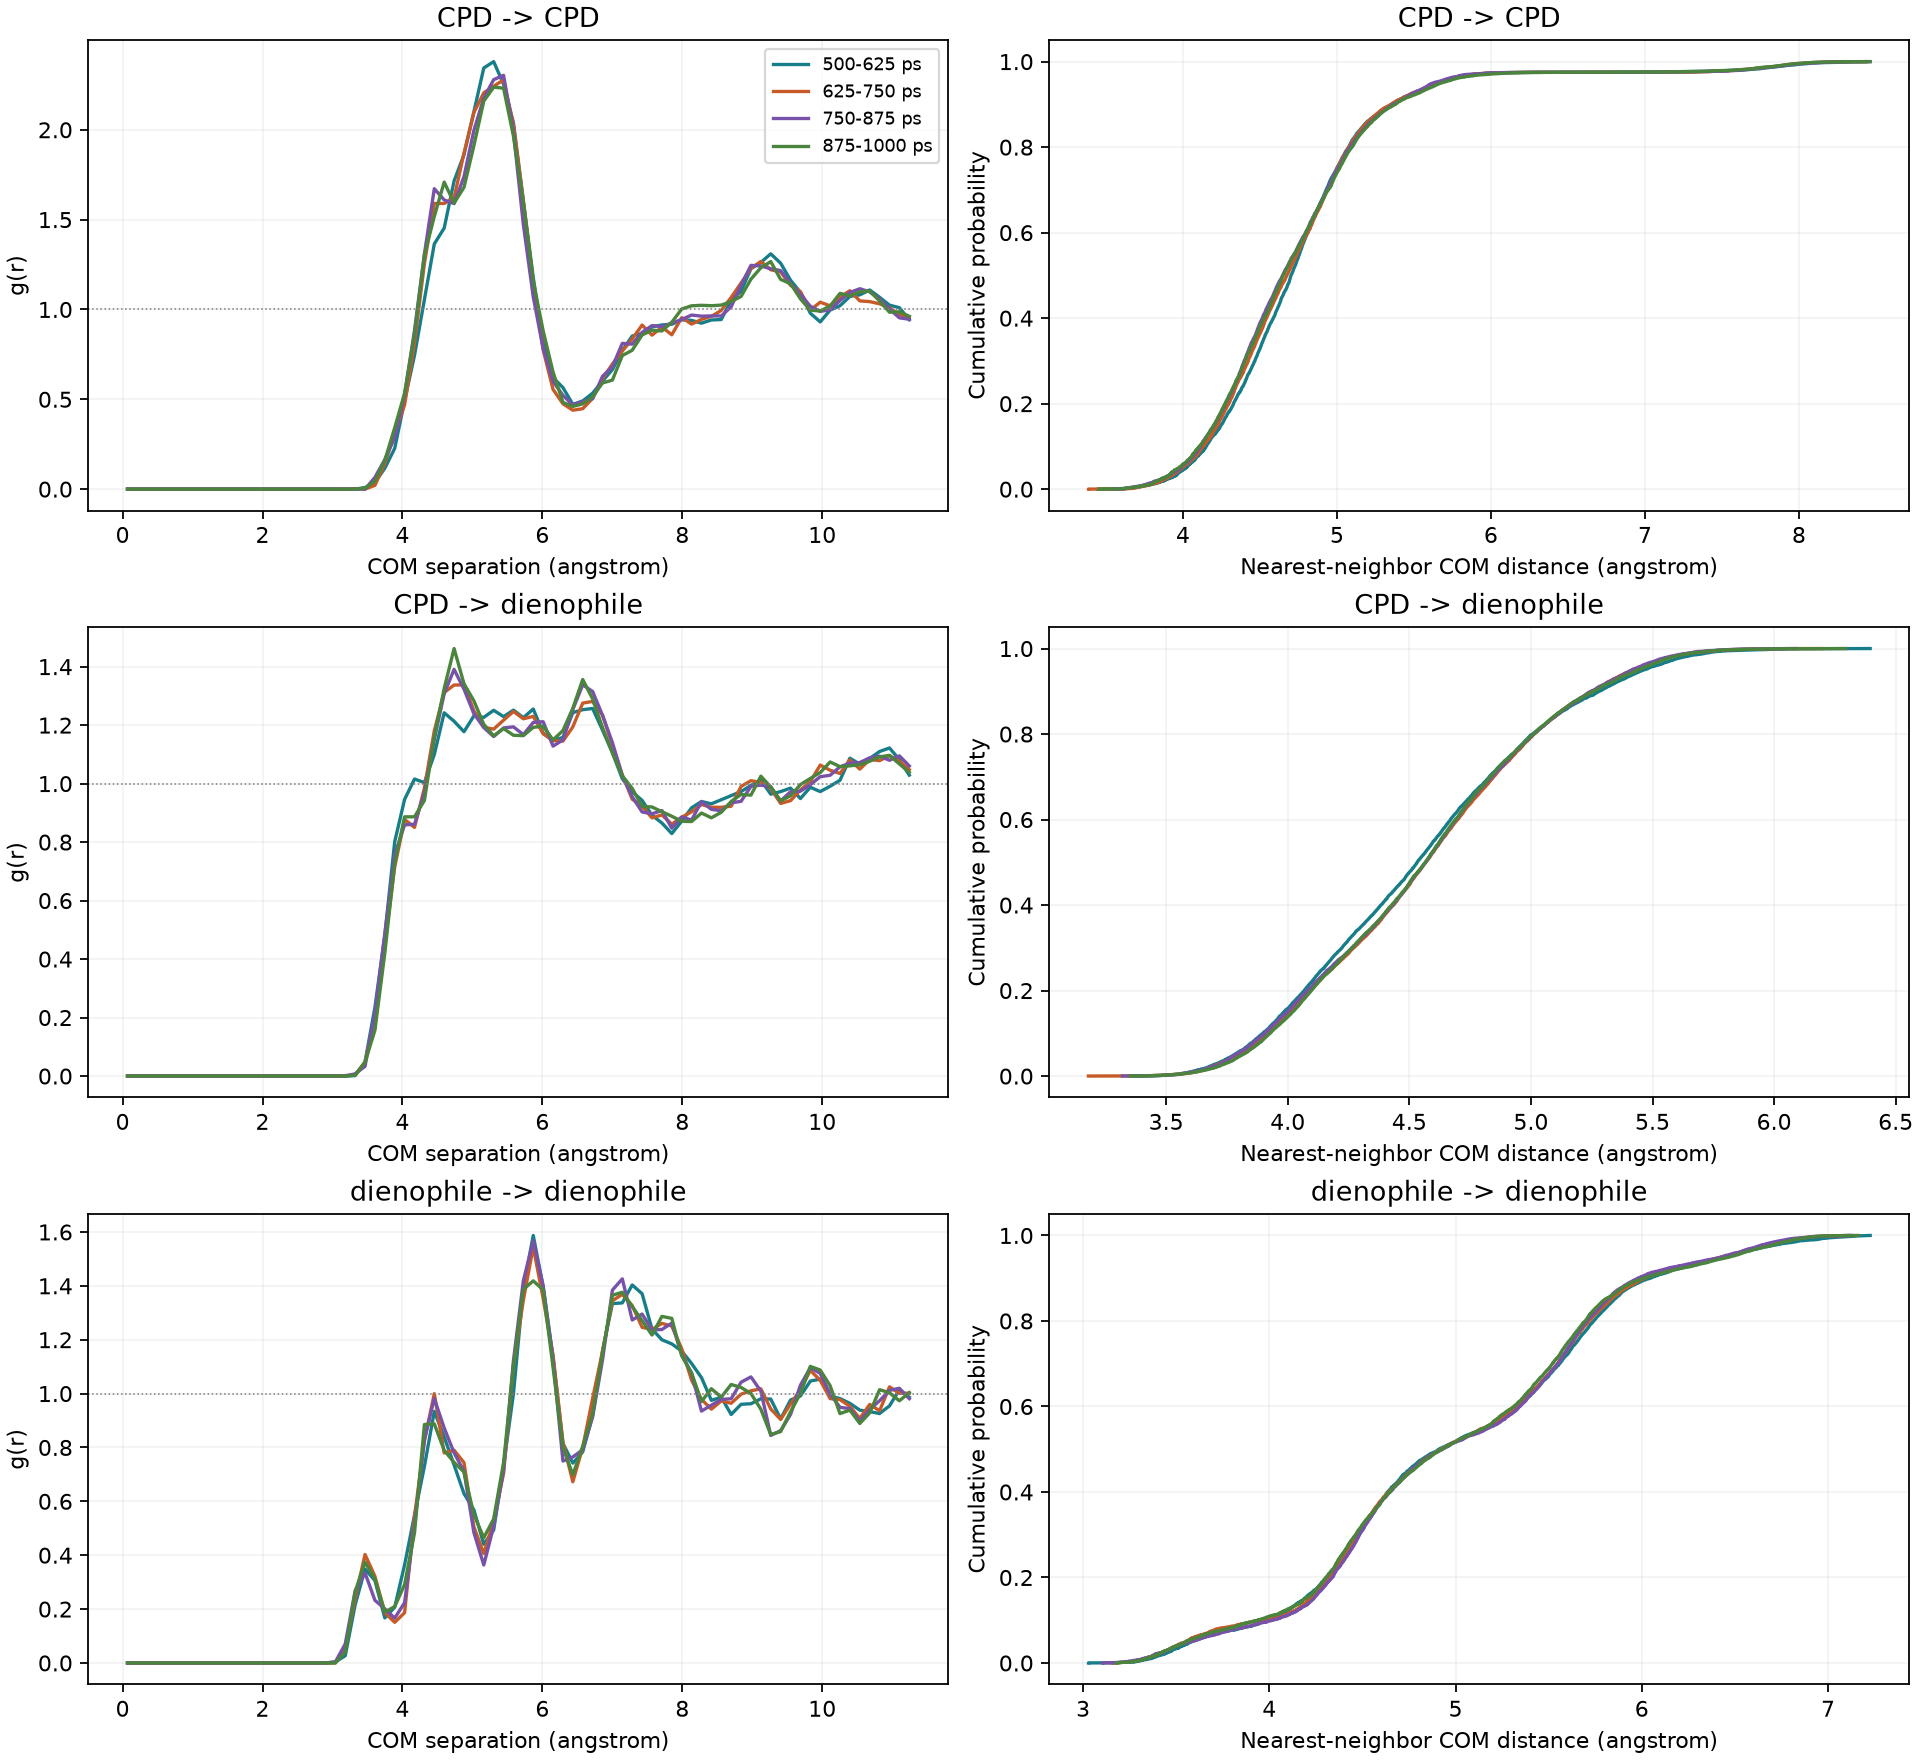

In [8]:
from IPython.display import Image, display

STABILITY_DIR = REPORT_DIR / "stability"
if not (STABILITY_DIR / "stability.json").exists():
    raise FileNotFoundError("Run python -m examples.analyze_npt_stability first")
stability = json.loads((STABILITY_DIR / "stability.json").read_text())
for filename in ("scalar_stability.png", "structural_stability.png"):
    display(Image(filename=str(STABILITY_DIR / filename)))
